# Visualize the SAMap transferred-label object

Reads the deliverable `*_transferred.h5ad` (produced by `samap_transferred_object`) and plots the
transfer results directly off `obs` — no 7 GB pkl, no recomputation. This is the same view as the
earlier inspection notebook, but from the finished object, so it's what your collaborator runs too.

**Kernel:** any env with `scanpy`/`anndata` — the samap kernel works, but so does `rsc_uv`, since
this only reads an h5ad (no `samap`/`hnswlib`, so no gcc-14 requirement).

Pick the run in the config cell.

In [1]:
# --- config -------------------------------------------------------------------------------
RESULTS = "/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/samap_transfer"
RUN = "secretory_x_1dpi_late_hmmer"          # or "secretory_x_1dpi_late_hmmer"

import anndata as ad, numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

a = ad.read_h5ad(f"{RESULTS}/{RUN}_transferred.h5ad")
print(a.shape, "| obsm:", list(a.obsm), "| obs:", list(a.obs.columns))
is_h = (a.obs["species"] == "hs").values
is_m = (a.obs["species"] == "mm").values
print(f"human {int(is_h.sum())}  mouse {int(is_m.sum())}")

(34228, 70299) | obsm: ['X_umap', 'spatial'] | obs: ['hs_sample', 'hs_cell_barcode', 'hs_timepoint', 'hs_coarse_refined', 'hs_fine_refined', 'hs_origin_lineage', 'hs_lineage', 'hs_cell_type', 'hs_subtype', 'hs_annotation_level', 'hs_cell_type_annotations', 'hs_cell_subtype_annotations', 'hs_leiden_clusters', 'mm_sample', 'mm_cell_barcode', 'mm_timepoint', 'mm_coarse_refined', 'mm_fine_refined', 'mm_origin_lineage', 'mm_cell_type_annotations', 'mm_cell_subtype_annotations', 'mm_leiden_clusters', 'batch', 'species', 'cell_type_independent', 'cell_type_transferred', 'transferred_frac_decidual', 'cell_subtype']
human 23441  mouse 10787


## 1. Label counts — independent vs transferred, per species

In [2]:
for nm, m in [("HUMAN", is_h), ("MOUSE", is_m)]:
    print(f"=== {nm} ===")
    print("  independent:", dict(a.obs.loc[m, "cell_type_independent"].value_counts()))
    print("  transferred:", dict(a.obs.loc[m, "cell_type_transferred"].value_counts()))
print("\nmouse fine subtypes:", dict(list(a.obs.loc[is_m, "cell_subtype"].value_counts().items())[:12]))

=== HUMAN ===
  independent: {'endometrial fibroblast': np.int64(17891), 'decidual': np.int64(5550)}
  transferred: {'endometrial fibroblast': np.int64(12265), 'decidual': np.int64(11155), 'no cross-species neighbor': np.int64(21)}
=== MOUSE ===
  independent: {'decidual': np.int64(5654), 'endometrial fibroblast': np.int64(5133)}
  transferred: {'endometrial fibroblast': np.int64(6967), 'decidual': np.int64(3819), 'no cross-species neighbor': np.int64(1)}

mouse fine subtypes: {'dec2': 3818, 'eFib2i': 3734, 'dec1': 1233, 'eFib3': 724, 'dec3': 472, 'eFib1': 362, 'eFibP': 161, 'eFib2': 152, 'decAp': 131, '': 0}


## 2. Confusion matrices — independent (rows) vs transferred (cols)

Diagonal = agreement; the fibroblast->decidual off-diagonal is the decidualization-transition bleed.

In [3]:
for nm, m in [("HUMAN", is_h), ("MOUSE", is_m)]:
    ct = pd.crosstab(a.obs.loc[m, "cell_type_independent"],
                     a.obs.loc[m, "cell_type_transferred"])
    print(f"=== {nm} (n={int(m.sum())}) ===\n{ct}\n")

=== HUMAN (n=23441) ===
cell_type_transferred   decidual  endometrial fibroblast  \
cell_type_independent                                      
decidual                    4323                    1227   
endometrial fibroblast      6832                   11038   

cell_type_transferred   no cross-species neighbor  
cell_type_independent                              
decidual                                        0  
endometrial fibroblast                         21  

=== MOUSE (n=10787) ===
cell_type_transferred   decidual  endometrial fibroblast  \
cell_type_independent                                      
decidual                    3592                    2062   
endometrial fibroblast       227                    4905   

cell_type_transferred   no cross-species neighbor  
cell_type_independent                              
decidual                                        0  
endometrial fibroblast                          1  



## 3. Joint SAMap co-embedding (BOTH species together)

This is the cross-species view — `X_umap` is co-registered, so plotting both species on it is valid.
Left: colored by species. Middle: independent label. Right: transferred label.

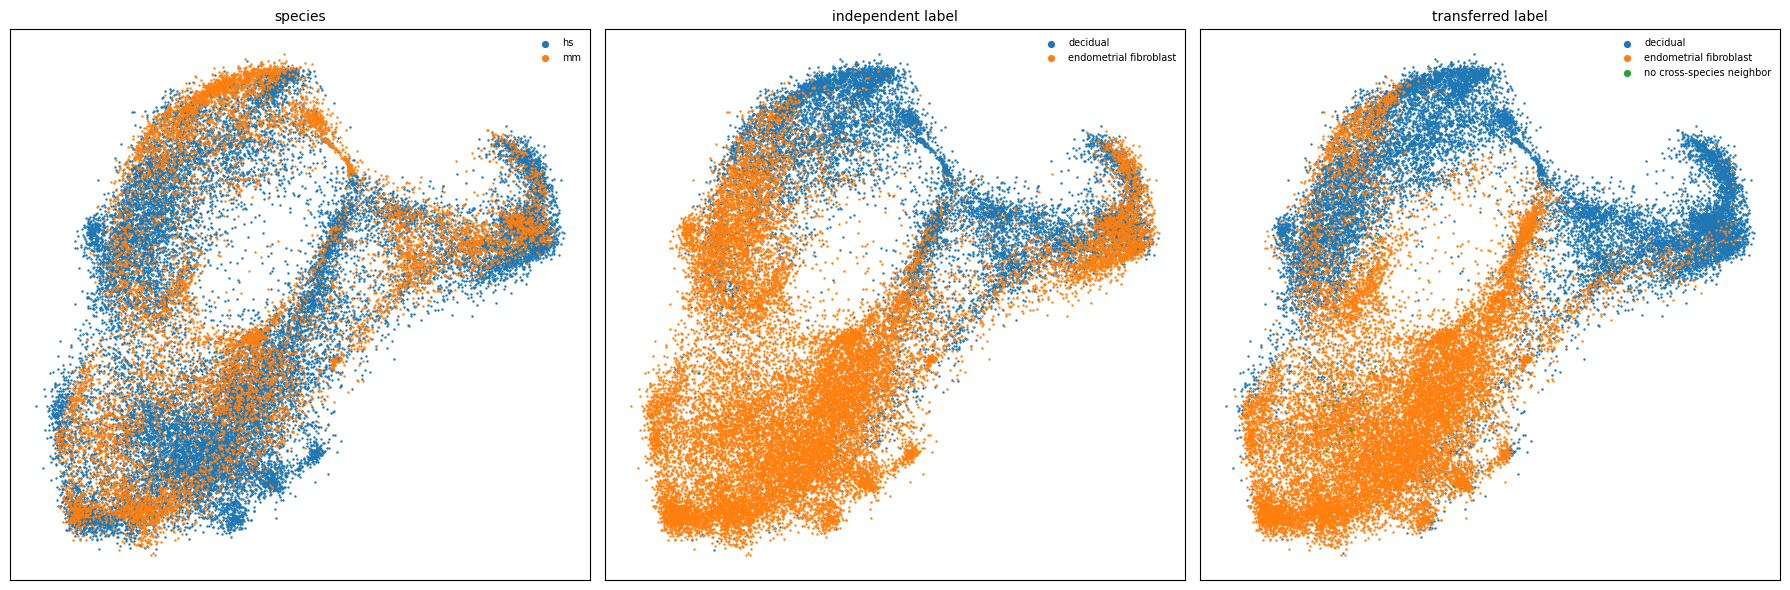

In [4]:
U = a.obsm["X_umap"]
def umap_panel(ax, values, title, cats=None):
    vals = pd.Series(np.asarray(values), index=a.obs_names)
    cats = cats if cats is not None else sorted(vals.dropna().unique())
    cmap = plt.get_cmap("tab10")
    for i, c in enumerate(cats):
        mm = (vals == c).values
        ax.scatter(U[mm, 0], U[mm, 1], s=3, color=cmap(i % 10), label=str(c), linewidths=0)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(markerscale=3, fontsize=7, loc="best", frameon=False)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
umap_panel(ax[0], a.obs["species"], "species", cats=["hs", "mm"])
umap_panel(ax[1], a.obs["cell_type_independent"], "independent label")
umap_panel(ax[2], a.obs["cell_type_transferred"], "transferred label")
plt.tight_layout(); plt.show()

## 4. Continuous transfer — decidual fraction on the joint UMAP

`transferred_frac_decidual` is the pre-threshold 0–1 vote; smoother than the binary call and shows
the gradient across the transition.

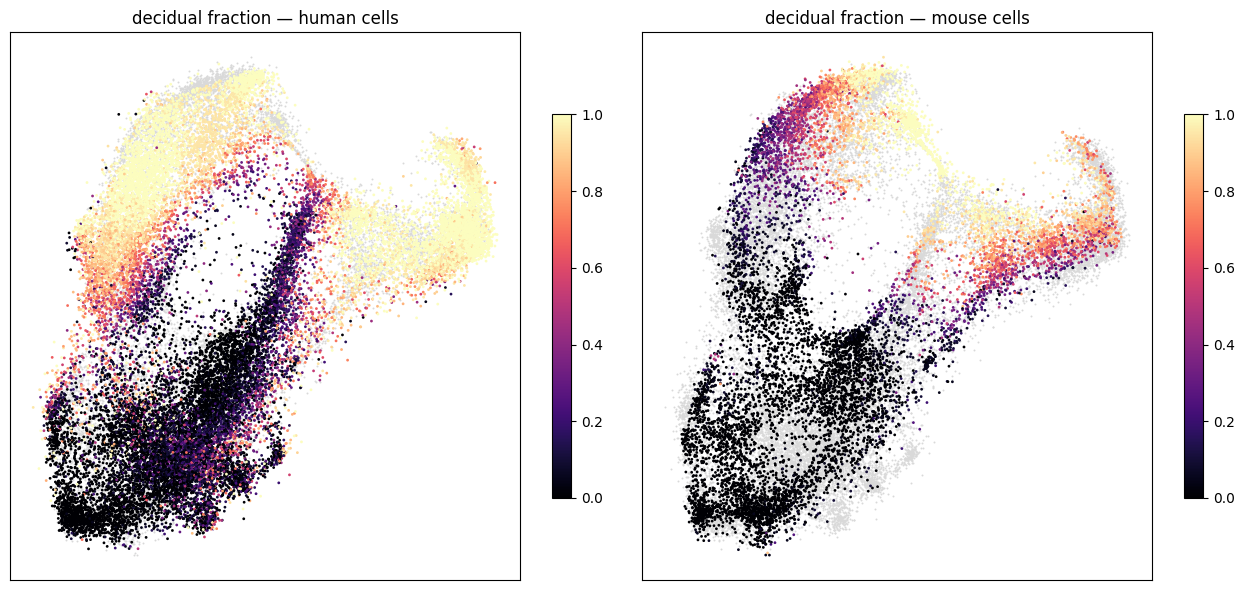

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
for k, (nm, m) in enumerate([("human cells", is_h), ("mouse cells", is_m)]):
    sc = ax[k].scatter(U[m, 0], U[m, 1], c=a.obs["transferred_frac_decidual"].values[m],
                       s=4, cmap="magma", vmin=0, vmax=1, linewidths=0)
    ax[k].scatter(U[~m, 0], U[~m, 1], s=2, color="0.85", linewidths=0, zorder=0)
    ax[k].set_title(f"decidual fraction — {nm}"); ax[k].set_xticks([]); ax[k].set_yticks([])
    plt.colorbar(sc, ax=ax[k], shrink=0.7)
plt.tight_layout(); plt.show()

## 5. Spatial — per species (subset first; the two coord systems are NOT co-registered)

Pink-on-grey, the stain view: independent vs transferred decidual, per species, on `obsm['spatial']`.
Flip `LABEL` to see fibroblasts.

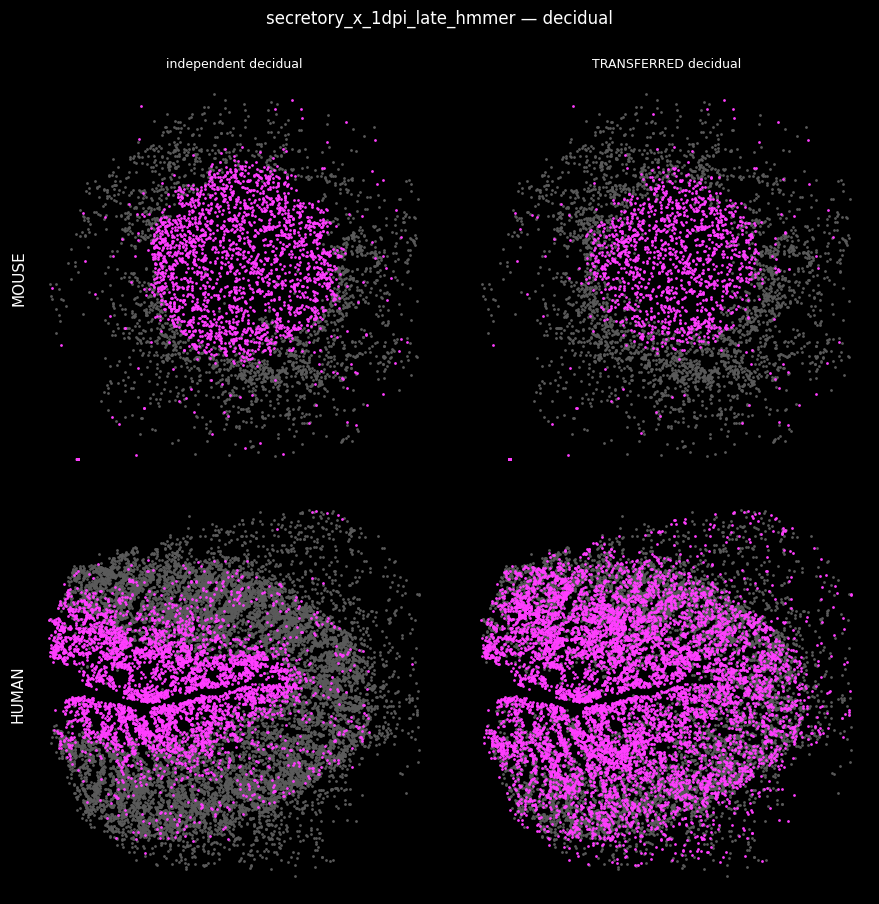

In [6]:
LABEL = "decidual"                         # "decidual" | "endometrial fibroblast"
XY = a.obsm["spatial"]; PINK, GREY = "#FF3DFF", "#5a5a5a"

def spatial_panel(ax, smask, lab_col, title):
    ax.set_facecolor("black")
    m = smask & np.isfinite(XY[:, 0]) & np.isfinite(XY[:, 1])
    lit = (a.obs[lab_col].values == LABEL)
    ax.scatter(XY[m & ~lit, 0], XY[m & ~lit, 1], s=4, c=GREY, linewidths=0)
    ax.scatter(XY[m &  lit, 0], XY[m &  lit, 1], s=4, c=PINK, linewidths=0)
    ax.set_title(title, color="white", fontsize=9); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(2, 2, figsize=(9, 9)); fig.patch.set_facecolor("black")
for r, (nm, sm) in enumerate([("MOUSE", is_m), ("HUMAN", is_h)]):
    spatial_panel(ax[r, 0], sm, "cell_type_independent", f"independent {LABEL}" if r == 0 else "")
    spatial_panel(ax[r, 1], sm, "cell_type_transferred", f"TRANSFERRED {LABEL}" if r == 0 else "")
    ax[r, 0].set_ylabel(nm, color="white", fontsize=11)
plt.suptitle(f"{RUN} — {LABEL}", color="white", y=1.0); plt.tight_layout(); plt.show()